In [94]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


data cleaning

In [ ]:
data = pd.read_csv(r'D:\instant\super store project\final_super_store_project\Sample - Superstore - Sample - Superstore.csv')
print("shape : ", data.shape)
print("\ndata info : ", data.info())

shape :  (9994, 21)
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18 

In [11]:
data['Ship Date'] = pd.to_datetime(data['Ship Date'])
data['Order Date'] = pd.to_datetime(data['Order Date'])
data[['Order Date', 'Ship Date']].dtypes

Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object

In [13]:
print("duplicated rows : ", data.duplicated().sum())
print("unique rowID : ", data['Row ID'].nunique())
print("Unique Order IDs:", data["Order ID"].nunique())

duplicated rows :  0
unique rowID :  9994
Unique Order IDs: 5009


In [14]:
data[["Sales", "Quantity", "Discount", "Profit"]].describe()

,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000


question 1 : What is the store's business KPIs?

In [36]:
total_sales = data['Sales'].sum()
print("total sales : ", total_sales)
total_profit = data['Profit'].sum()
print("total profit : ", total_profit)
total_unique_orders = data['Order ID'].nunique()
print("total unique orders : ", total_unique_orders)
total_profit_margin = (total_profit / total_sales) * 100
print("total profit margin : ", total_profit_margin,"% from every 100$ of sales")

total sales :  2297200.8603
total profit :  286397.0217
total unique orders :  5009
total profit margin :  12.467217240315605 % from every 100$ of sales


question 2 : sales and profit trends

In [39]:
data["year-trends"] = data['Order Date'].dt.year
TrendYear = data.groupby("year-trends").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum")
)
TrendYear["Profit Margin (%)"] = (
    TrendYear["Profit"] / TrendYear["Sales"] * 100
)

print(TrendYear)

                   Sales      Profit  Profit Margin (%)
year-trends                                            
2014         484247.4981  49543.9741          10.231126
2015         470532.5090  61618.6037          13.095504
2016         609205.5980  81795.1743          13.426530
2017         733215.2552  93439.2696          12.743771


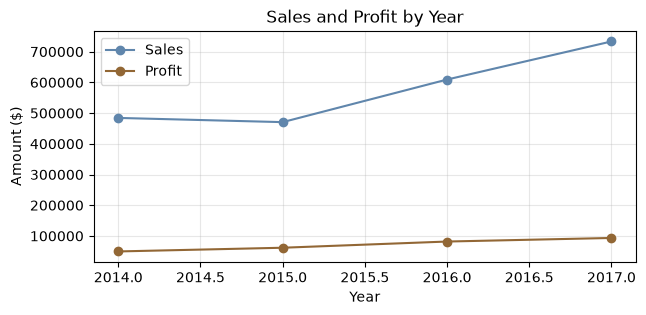

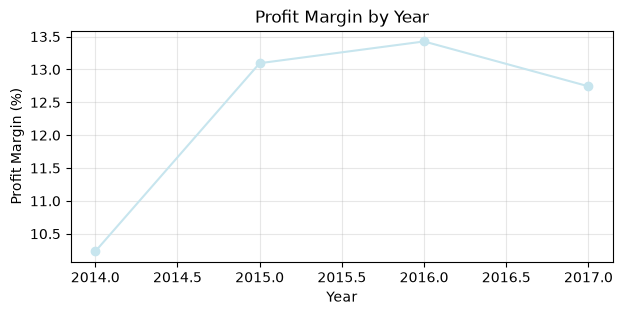

In [43]:
TrendYear[["Sales", "Profit"]].plot(
    kind="line", marker="o", figsize=(7, 3) , color=['#6086AC','#926735']
)
plt.title("Sales and Profit by Year")
plt.xlabel("Year")
plt.ylabel("Amount ($)")
plt.grid(True, alpha=0.3)
plt.show()

TrendYear["Profit Margin (%)"].plot(
    kind="line", marker="o", figsize=(7, 3) , color=['#C7E5EE']
)
plt.title("Profit Margin by Year")
plt.xlabel("Year")
plt.ylabel("Profit Margin (%)")
plt.grid(True, alpha=0.3)
plt.show()

In [61]:
def line_chart(series, title, xlabel="", ylabel="", color=None, figsize=(10, 5)):
    ax = series.plot(kind="line", marker="o", figsize=figsize, color=color)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

question 3 : best month for sales

,Sales,Profit,Years_Observed,Average Sales per Year
Month,,,,
1,94924.8356,9134.4461,4,23731.208900
2,59751.2514,10294.6107,4,14937.812850
3,205005.4888,28594.6872,4,51251.372200
4,137762.1286,11587.4363,4,34440.532150
5,155028.8117,22411.3078,4,38757.202925
6,152718.6793,21285.7954,4,38179.669825
7,147238.0970,13832.6648,4,36809.524250
8,159044.0630,21776.9384,4,39761.015750
9,307649.9457,36857.4753,4,76912.486425


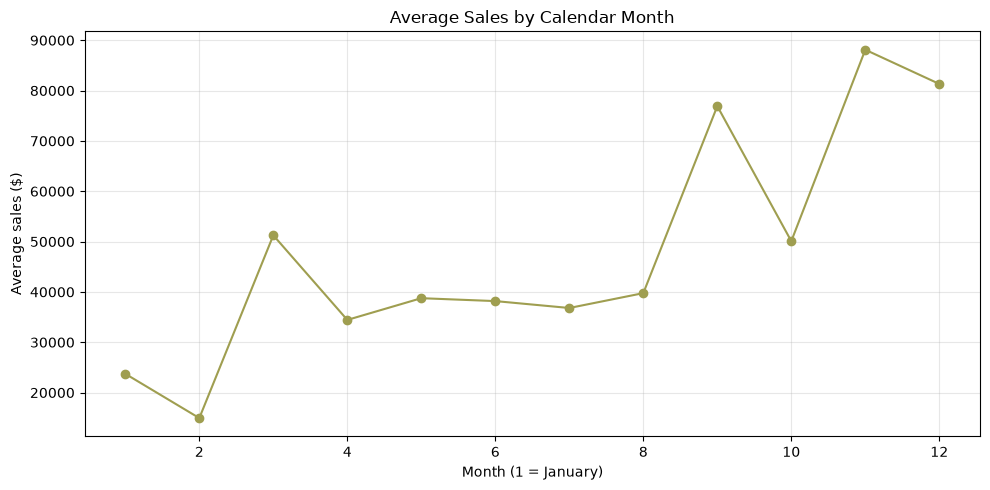

In [62]:
data["Month"] = data["Order Date"].dt.month
month = data.groupby("Month").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Years_Observed=("year-trends", "nunique")
)

month["Average Sales per Year"] = (month["Sales"] / month["Years_Observed"])

display(month)

line_chart(
    month["Average Sales per Year"],
    "Average Sales by Calendar Month",
    "Month (1 = January)", "Average sales ($)",
    "#9F9E50"
)

In [69]:
def profit_margin(grouped):
    return grouped["Profit"].div(grouped["Sales"]).mul(100)

In [76]:
def bar_chart(series, title, xlabel="", ylabel="", color=None,figsize=(10, 5)):
    ax = series.plot(kind="bar", figsize=figsize)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

question 4 : which product category generate sales / profit 

,Sales,Profit,Profit Margin (%)
Category,,,
Technology,836154.0330,145454.9481,17.395712
Furniture,741999.7953,18451.2728,2.486695
Office Supplies,719047.0320,122490.8008,17.035158


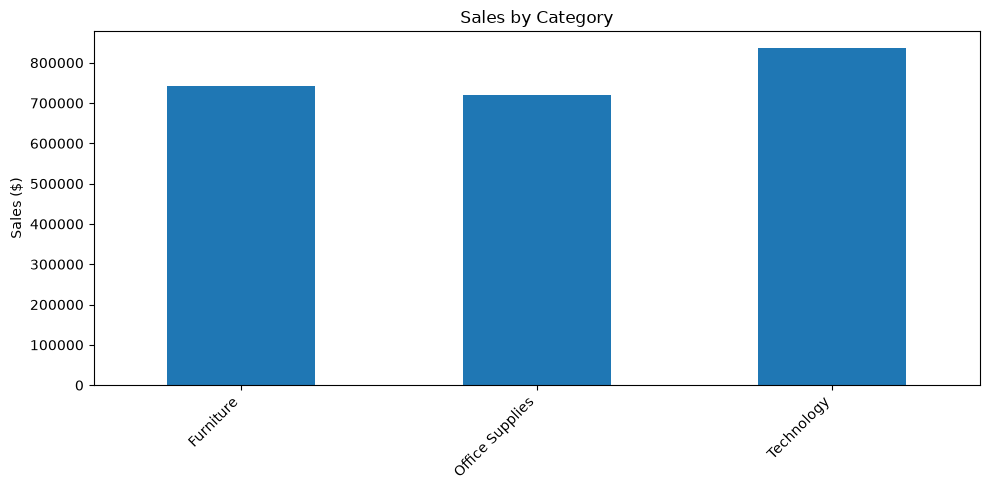

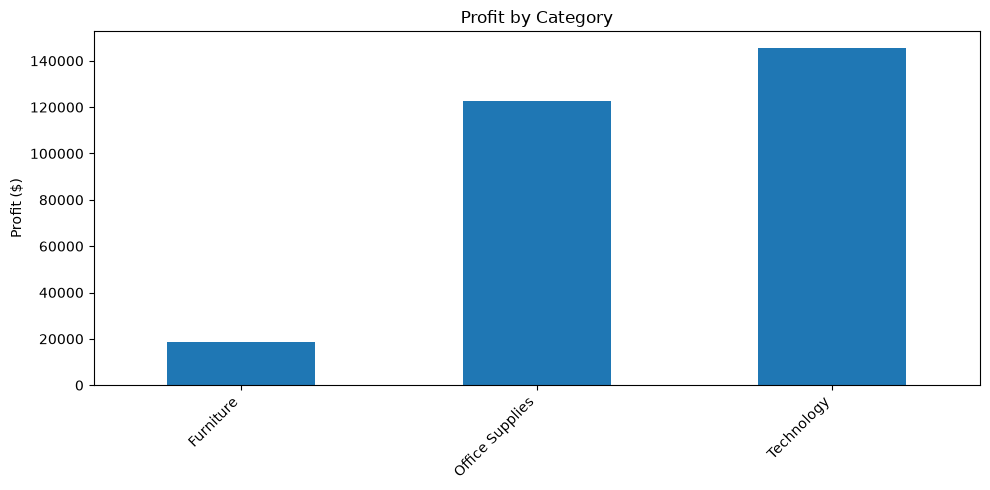

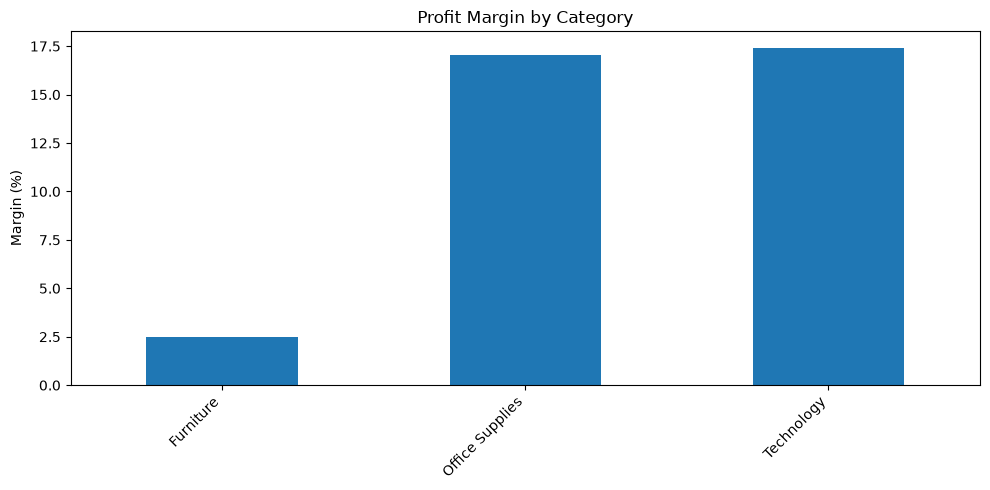

In [79]:
category = data.groupby("Category").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
category["Profit Margin (%)"] = profit_margin(category)
display(category.sort_values("Sales", ascending=False))
bar_chart(category["Sales"], "Sales by Category", ylabel="Sales ($)")
bar_chart(category["Profit"], "Profit by Category", ylabel="Profit ($)")
bar_chart(category["Profit Margin (%)"], "Profit Margin by Category", ylabel="Margin (%)")


question 5 : which subcatergory generate the most/least profit

,Sales,Profit
Sub-Category,,
Tables,206965.5320,-17725.4811
Bookcases,114879.9963,-3472.5560
Supplies,46673.5380,-1189.0995
Fasteners,3024.2800,949.5182
Machines,189238.6310,3384.7569
Labels,12486.3120,5546.2540
Art,27118.7920,6527.7870
Envelopes,16476.4020,6964.1767
Furnishings,91705.1640,13059.1436


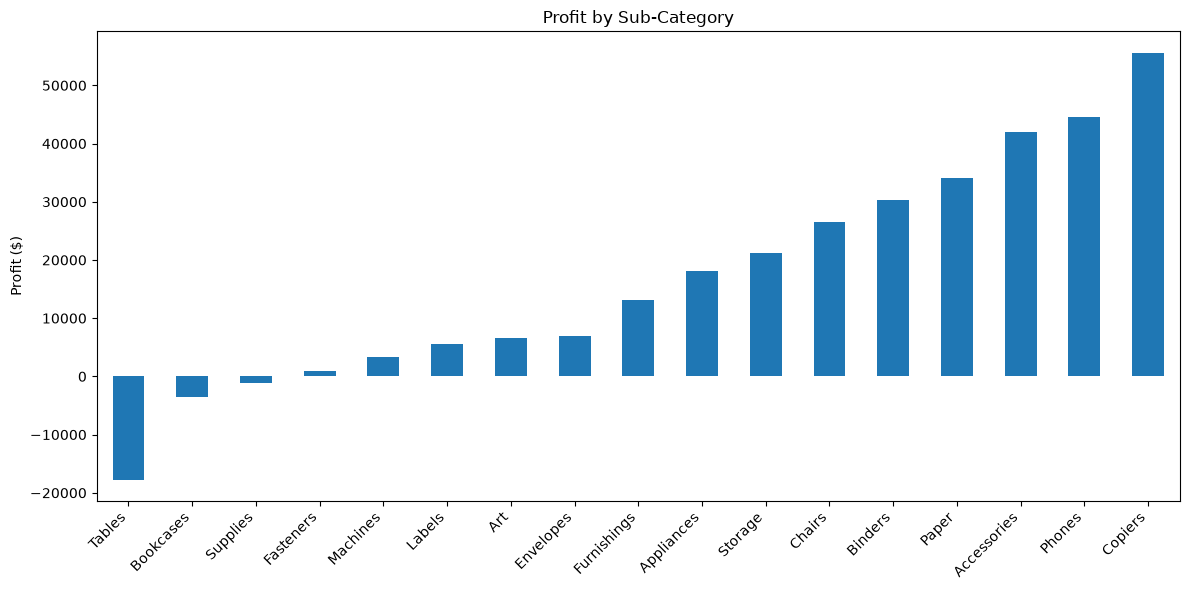

In [80]:
subcategory = data.groupby("Sub-Category").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum")
).sort_values("Profit")
display(subcategory)
bar_chart(subcategory["Profit"], "Profit by Sub-Category", ylabel="Profit ($)", figsize=(12, 6))


question 6 : how discount rate affect profit

,Sales,Profit,Lines,Profit Margin (%)
Discount,,,,
0.00,1.087908e+06,320987.6032,4798,29.505019
0.10,5.436935e+04,9029.1770,94,16.607108
0.15,2.755852e+04,1418.9915,52,5.149012
0.20,7.645944e+05,90337.3060,3657,11.815063
0.30,1.032267e+05,-10369.2774,227,-10.045155
0.32,1.449346e+04,-2391.1377,27,-16.498047
0.40,1.164178e+05,-23057.0504,206,-19.805437
0.45,5.484974e+03,-2493.1111,11,-45.453472
0.50,5.891854e+04,-20506.4281,66,-34.804712


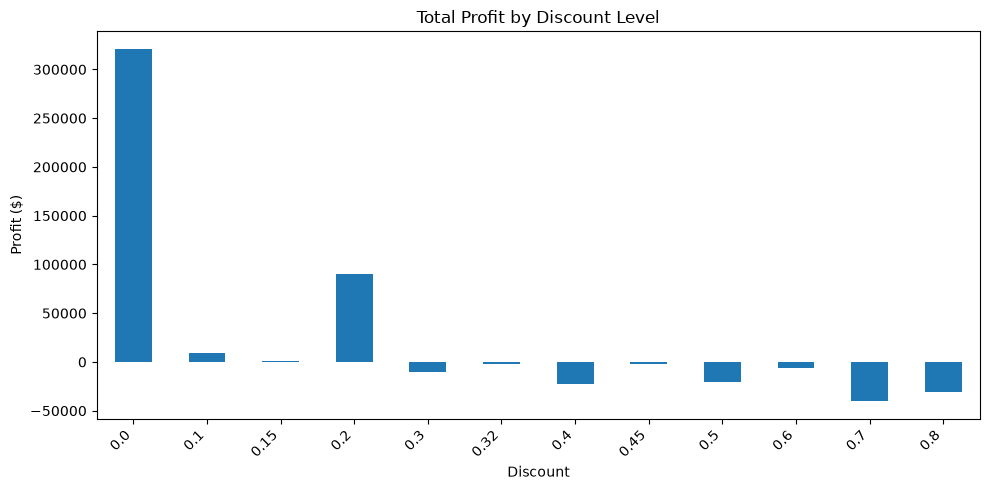

In [81]:
discount_profit = data.groupby("Discount").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Lines=("Profit", "size")
)
discount_profit["Profit Margin (%)"] = profit_margin(discount_profit)
display(discount_profit)
bar_chart(discount_profit["Profit"], "Total Profit by Discount Level",
          xlabel="Discount", ylabel="Profit ($)")


question 7 : which region perform best on (sales,profit,margin)

,Sales,Profit,Profit Margin (%)
Region,,,
West,725457.8245,108418.4489,14.944831
East,678781.2400,91522.7800,13.483399
South,391721.9050,46749.4303,11.934342
Central,501239.8908,39706.3625,7.921629


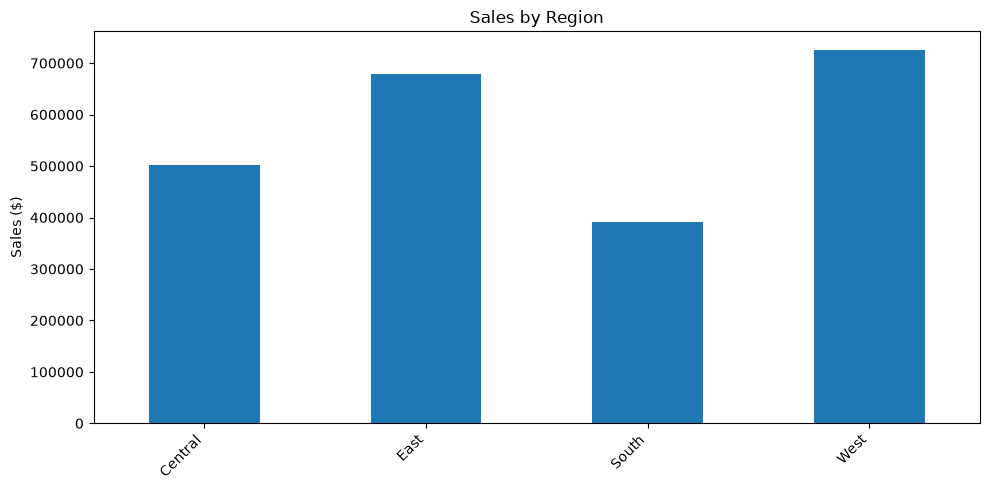

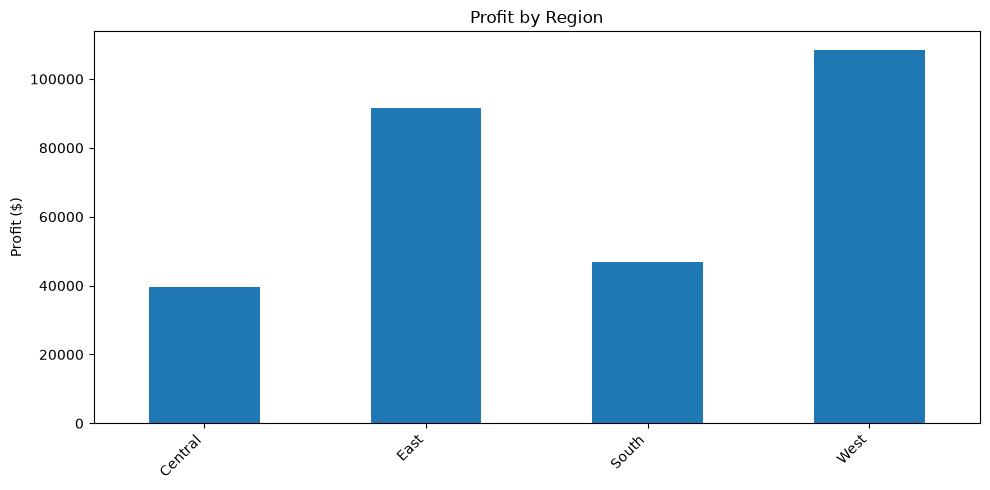

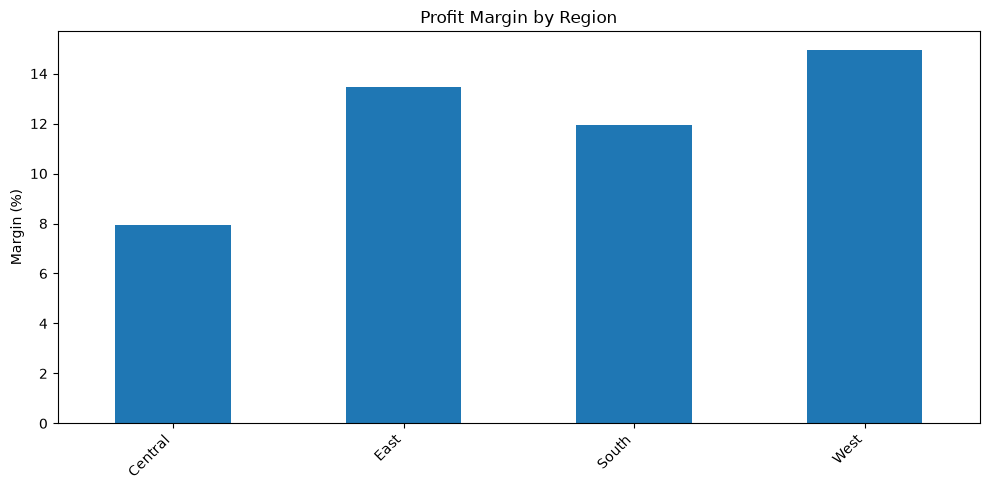

In [82]:
regions = data.groupby("Region").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
regions["Profit Margin (%)"] = profit_margin(regions)
display(regions.sort_values("Profit", ascending=False))
bar_chart(regions["Sales"], "Sales by Region", ylabel="Sales ($)")
bar_chart(regions["Profit"], "Profit by Region", ylabel="Profit ($)")
bar_chart(regions["Profit Margin (%)"], "Profit Margin by Region", ylabel="Margin (%)")


question 8 : which state generates the most/least profit

,Sales,Profit,Profit Margin (%)
State,,,
California,457687.6315,76381.3871,16.688541
New York,310876.2710,74038.5486,23.816082
Washington,138641.2700,33402.6517,24.092863
Michigan,76269.6140,24463.1876,32.074618
Virginia,70636.7200,18597.9504,26.329012
Indiana,53555.3600,18382.9363,34.325110
Georgia,49095.8400,16250.0433,33.098615
Kentucky,36591.7500,11199.6966,30.607163
Minnesota,29863.1500,10823.1874,36.242618


,Sales,Profit,Profit Margin (%)
State,,,
Texas,170188.0458,-25729.3563,-15.118192
Ohio,78258.1360,-16971.3766,-21.686405
Pennsylvania,116511.9140,-15559.9603,-13.354823
Illinois,80166.1010,-12607.8870,-15.727205
North Carolina,55603.1640,-7490.9122,-13.472097
Colorado,32108.1180,-6527.8579,-20.330864
Tennessee,30661.8730,-5341.6936,-17.421289
Arizona,35282.0010,-3427.9246,-9.715789
Florida,89473.7080,-3399.3017,-3.799219


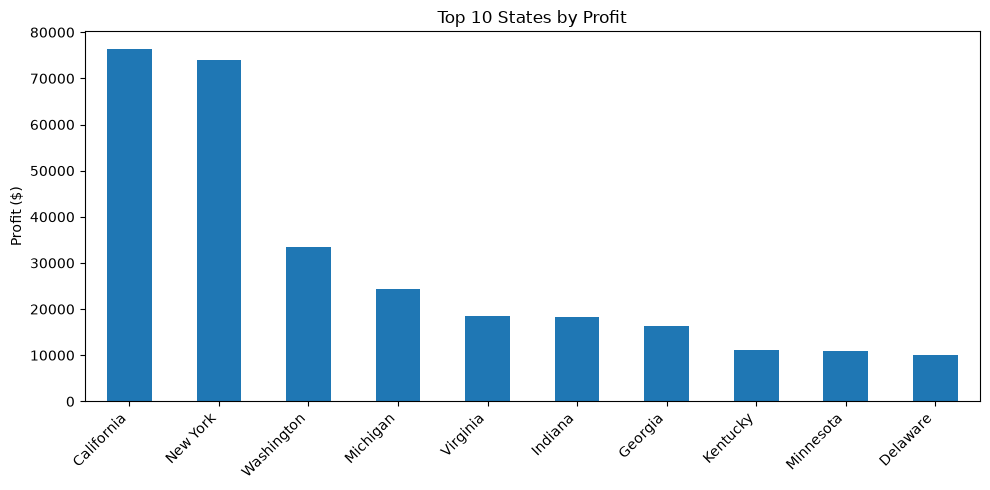

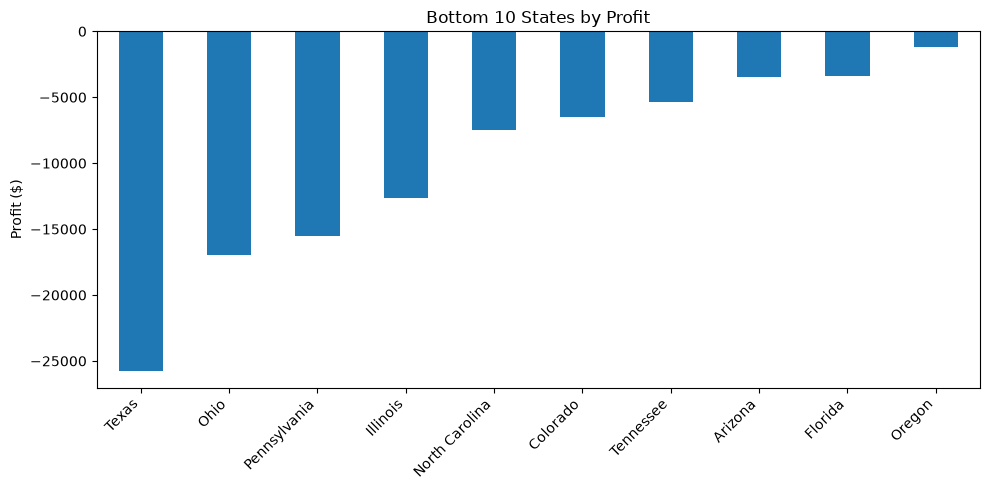

In [83]:
states = data.groupby("State").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
states["Profit Margin (%)"] = profit_margin(states)
display(states.nlargest(10, "Profit"))
display(states.nsmallest(10, "Profit"))
bar_chart(states.nlargest(10, "Profit")["Profit"], "Top 10 States by Profit",
          ylabel="Profit ($)")
bar_chart(states.nsmallest(10, "Profit")["Profit"], "Bottom 10 States by Profit",
          ylabel="Profit ($)")


question 9 : which cities generate most/least profit

,,Sales,Profit,Profit Margin (%)
State,City,,,
New York,New York City,256368.161,62036.9837,24.198396
California,Los Angeles,175851.341,30440.7579,17.310507
Washington,Seattle,119540.742,29156.0967,24.390092
California,San Francisco,112669.092,17507.3854,15.538765
Michigan,Detroit,42446.944,13181.7908,31.054746
Indiana,Lafayette,19630.450,8976.0973,45.725377
Delaware,Newark,20448.050,8086.1715,39.544952
Georgia,Atlanta,17197.840,6993.6629,40.665938
Minnesota,Minneapolis,16870.540,6824.5846,40.452674


Sales      Profit  Profit Margin (%)
State          City                                                    
Pennsylvania   Philadelphia  109077.0130 -13837.7674         -12.686236
Texas          Houston        64504.7604 -10153.5485         -15.740774
               San Antonio    21843.5280  -7299.0502         -33.415162
Ohio           Lancaster       8202.6250  -7149.6180         -87.162561
Illinois       Chicago        48539.5410  -6654.5688         -13.709583
North Carolina Burlington     12681.2820  -5894.5269         -46.482106
Colorado       Louisville      5070.4160  -3406.2095         -67.178107
Texas          Dallas         20131.9322  -2846.5257         -14.139357
Arizona        Phoenix        11000.2570  -2790.8832         -25.371073
Florida        Jacksonville   39133.3280  -2445.6608          -6.249560

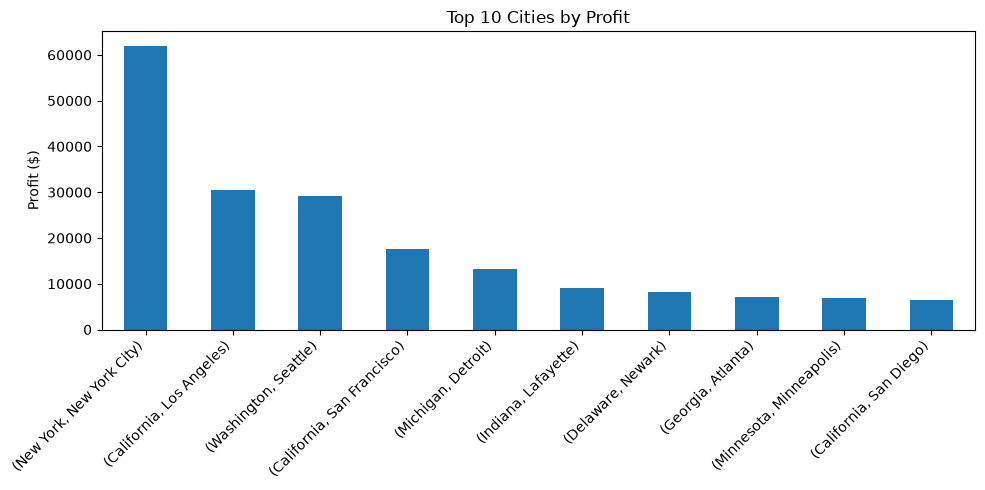

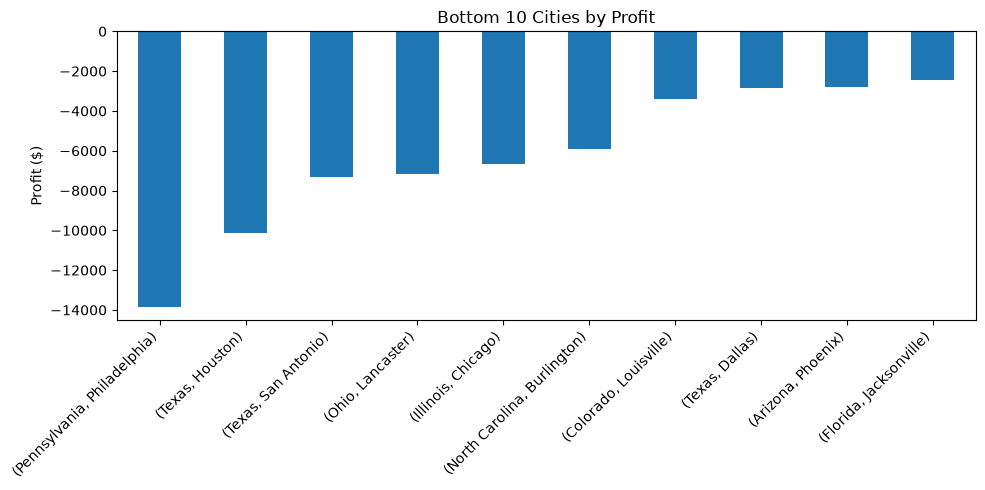

In [84]:
cities = data.groupby(["State", "City"]).agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
cities["Profit Margin (%)"] = profit_margin(cities)
display(cities.nlargest(10, "Profit"))
display(cities.nsmallest(10, "Profit"))
bar_chart(cities.nlargest(10, "Profit")["Profit"], "Top 10 Cities by Profit",
          ylabel="Profit ($)")
bar_chart(cities.nsmallest(10, "Profit")["Profit"], "Bottom 10 Cities by Profit",
          ylabel="Profit ($)")


question 10 : which customer segment with the most contribution

,Sales,Profit,Orders,Customers,Profit Margin (%)
Segment,,,,,
Consumer,1.161401e+06,134119.2092,2586,409,11.548050
Corporate,7.061464e+05,91979.1340,1514,236,13.025506
Home Office,4.296531e+05,60298.6785,909,148,14.034269


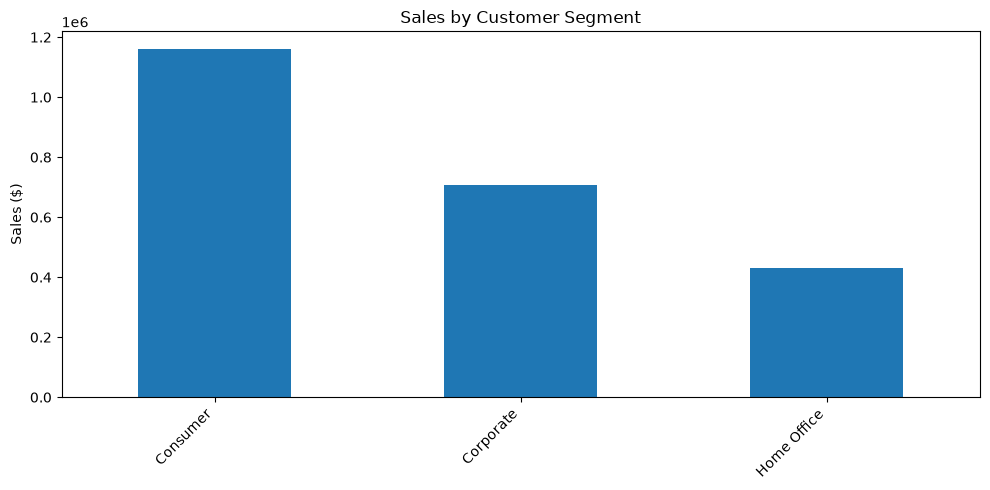

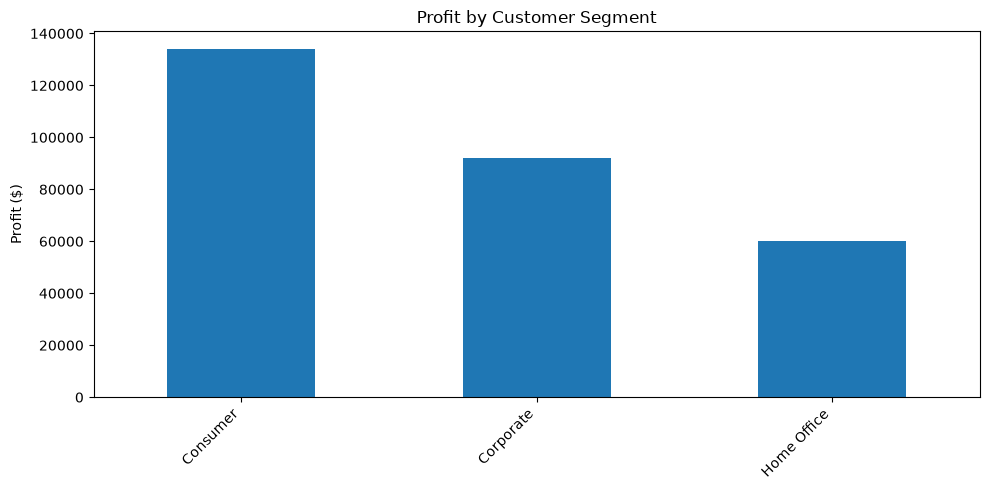

In [85]:
segments = data.groupby("Segment").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique"),
    Customers=("Customer ID", "nunique")
)
segments["Profit Margin (%)"] = profit_margin(segments)
display(segments)
bar_chart(segments["Sales"], "Sales by Customer Segment", ylabel="Sales ($)")
bar_chart(segments["Profit"], "Profit by Customer Segment", ylabel="Profit ($)")


question 11 : what are the shipping modescand their duration

,Order_Lines,Orders,Sales,Average_Shipping_Days,Median_Shipping_Days
Ship Mode,,,,,
First Class,1538,787,3.514284e+05,2.182705,2.0
Same Day,543,264,1.283631e+05,0.044199,0.0
Second Class,1945,964,4.591936e+05,3.238046,3.0
Standard Class,5968,2994,1.358216e+06,5.006535,5.0


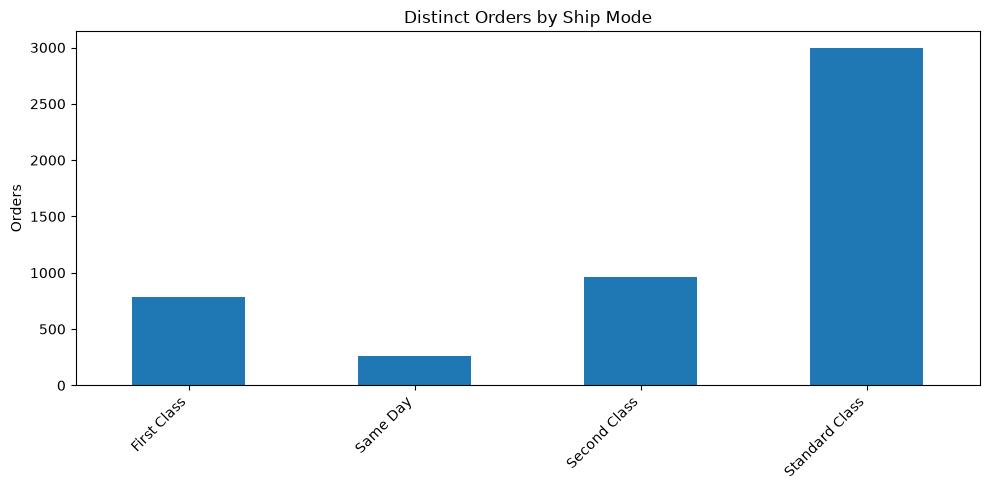

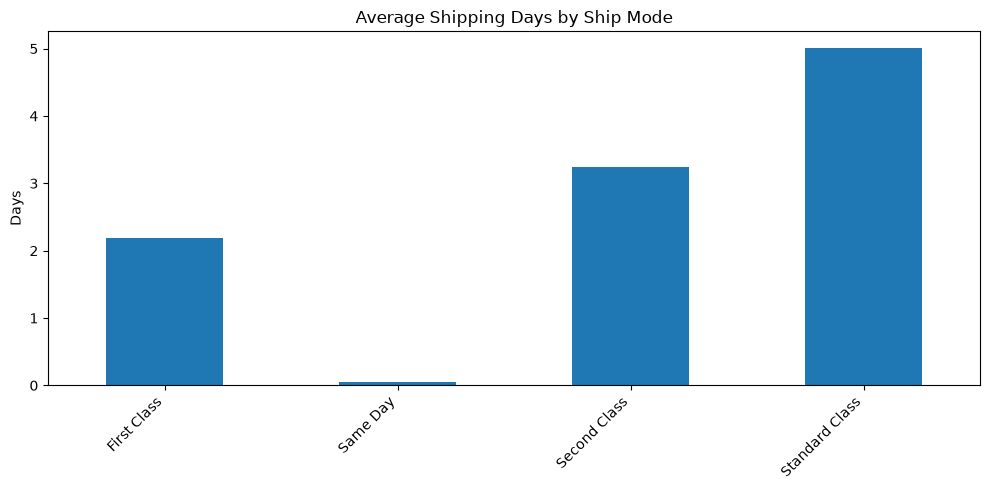

In [89]:
data["Shipping Days"] = (data["Ship Date"] - data["Order Date"]).dt.days

ship_modes = data.groupby("Ship Mode").agg(
    Order_Lines=("Order ID", "size"),
    Orders=("Order ID", "nunique"),
    Sales=("Sales", "sum"),
    Average_Shipping_Days=("Shipping Days", "mean"),
    Median_Shipping_Days=("Shipping Days", "median")
)
display(ship_modes)
bar_chart(ship_modes["Orders"], "Distinct Orders by Ship Mode", ylabel="Orders")
bar_chart(ship_modes["Average_Shipping_Days"], "Average Shipping Days by Ship Mode",ylabel="Days")


question 12 : Does average shipping time affected by ship mode and region?

Region,Central,East,South,West
Ship Mode,,,,
First Class,2.317726,2.224490,2.111111,2.097087
Same Day,0.033333,0.000000,0.012048,0.102703
Second Class,3.331183,3.266038,3.194529,3.167472
Standard Class,4.990271,4.967723,4.995893,5.058980


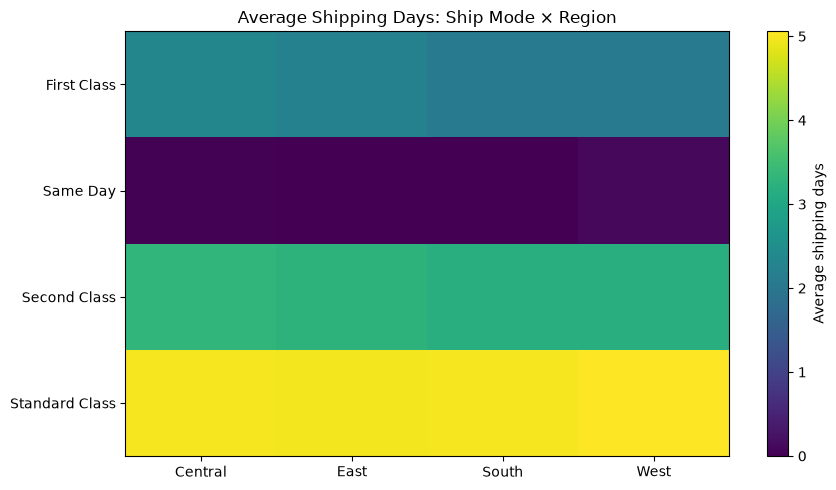

In [90]:
shipping_pivot = data.pivot_table(
    index="Ship Mode", columns="Region", values="Shipping Days", aggfunc="mean"
)
display(shipping_pivot)

plt.figure(figsize=(9, 5))
plt.imshow(shipping_pivot, aspect="auto")
plt.colorbar(label="Average shipping days")
plt.xticks(range(len(shipping_pivot.columns)), shipping_pivot.columns)
plt.yticks(range(len(shipping_pivot.index)), shipping_pivot.index)
plt.title("Average Shipping Days: Ship Mode × Region")
plt.tight_layout()
plt.show()


question 13 : top customers according to sales and profitts

,,Sales,Profit,Orders
Customer ID,Customer Name,,,
SM-20320,Sean Miller,25043.050,-1980.7393,5
TC-20980,Tamara Chand,19052.218,8981.3239,5
RB-19360,Raymond Buch,15117.339,6976.0959,6
TA-21385,Tom Ashbrook,14595.620,4703.7883,4
AB-10105,Adrian Barton,14473.571,5444.8055,10
KL-16645,Ken Lonsdale,14175.229,806.8550,12
SC-20095,Sanjit Chand,14142.334,5757.4119,9
HL-15040,Hunter Lopez,12873.298,5622.4292,6
SE-20110,Sanjit Engle,12209.438,2650.6769,11


,,Sales,Profit,Orders
Customer ID,Customer Name,,,
TC-20980,Tamara Chand,19052.218,8981.3239,5
RB-19360,Raymond Buch,15117.339,6976.0959,6
SC-20095,Sanjit Chand,14142.334,5757.4119,9
HL-15040,Hunter Lopez,12873.298,5622.4292,6
AB-10105,Adrian Barton,14473.571,5444.8055,10
TA-21385,Tom Ashbrook,14595.620,4703.7883,4
CM-12385,Christopher Martinez,8954.020,3899.8904,4
KD-16495,Keith Dawkins,8181.256,3038.6254,12
AR-10540,Andy Reiter,6608.448,2884.6208,6


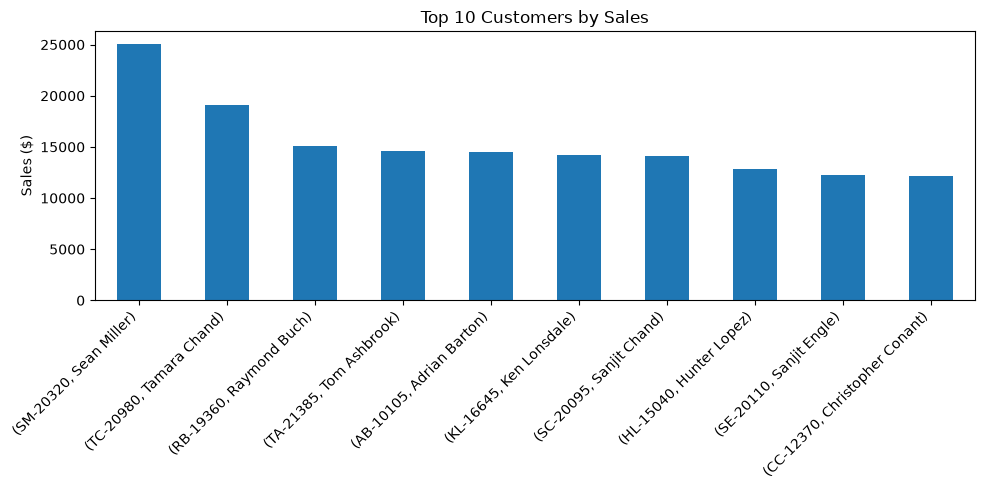

In [91]:
customers = data.groupby(["Customer ID", "Customer Name"]).agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique")
)
display(customers.nlargest(10, "Sales"))
display(customers.nlargest(10, "Profit"))
bar_chart(customers.nlargest(10, "Sales")["Sales"], "Top 10 Customers by Sales",
          ylabel="Sales ($)")


question 14 : what is the number of customers with repeated orders

Total customers                   793.000000
Customers with multiple orders    781.000000
Repeat customers (%)               98.486759
Average orders per customer         6.316520
Median orders per customer          6.000000
dtype: float64

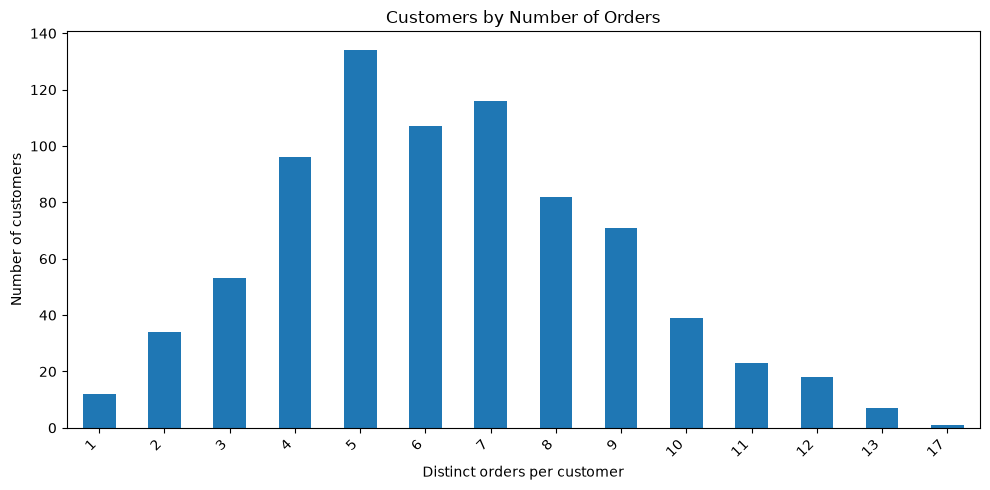

In [93]:
customer_orders = data.groupby("Customer ID")["Order ID"].nunique()
repeat_summary = pd.Series({
    "Total customers": len(customer_orders),
    "Customers with multiple orders": (customer_orders > 1).sum(),
    "Repeat customers (%)": (customer_orders > 1).mean() * 100,
    "Average orders per customer": customer_orders.mean(),
    "Median orders per customer": customer_orders.median()
})
display(repeat_summary)
bar_chart(customer_orders.value_counts().sort_index(), "Customers by Number of Orders",xlabel="Distinct orders per customer", ylabel="Number of customers",figsize=(10, 5))


question 15 : Are sales effected with a small share of customers or products?

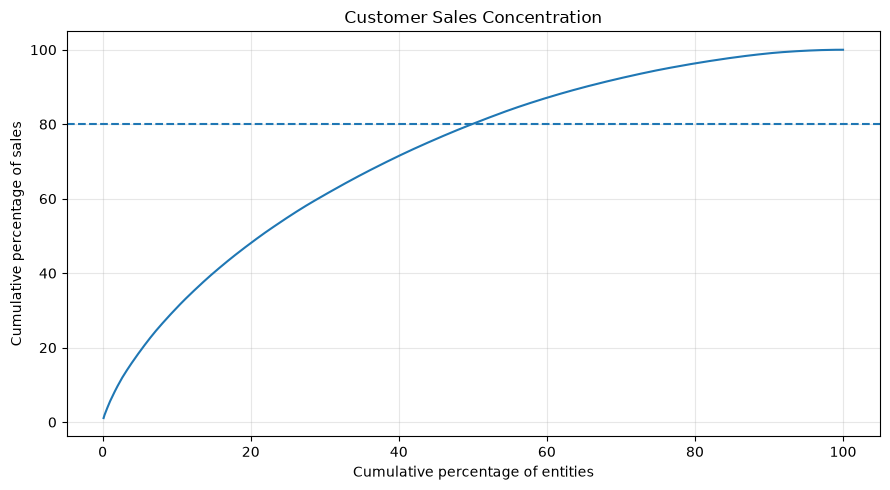

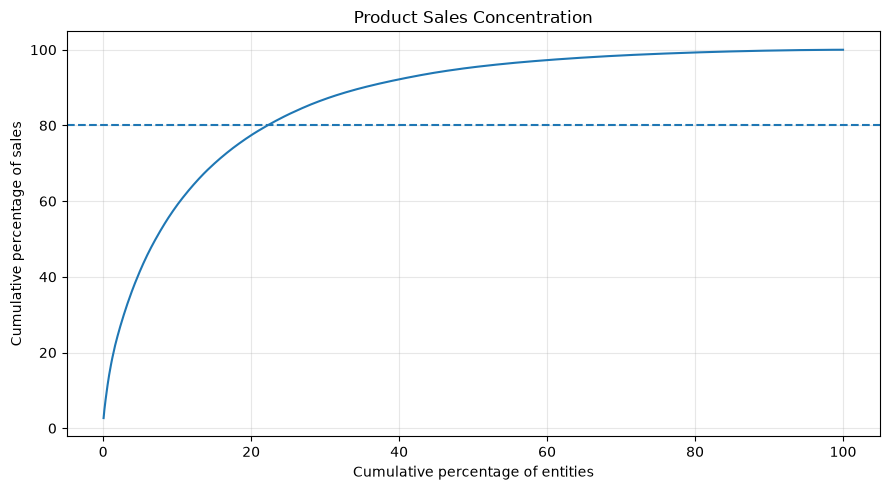

,Sales,Cumulative Sales (%),Cumulative Entities (%)
Customer ID,,,
SM-20320,25043.050,1.090155,0.126103
TC-20980,19052.218,1.919522,0.252207
RB-19360,15117.339,2.577598,0.378310
TA-21385,14595.620,3.212964,0.504414
AB-10105,14473.571,3.843016,0.630517
KL-16645,14175.229,4.460081,0.756620
SC-20095,14142.334,5.075715,0.882724
HL-15040,12873.298,5.636105,1.008827
SE-20110,12209.438,6.167597,1.134931


,Sales,Cumulative Sales (%),Cumulative Entities (%)
Product ID,,,
TEC-CO-10004722,61599.8240,2.681517,0.053706
OFF-BI-10003527,27453.3840,3.876596,0.107411
TEC-MA-10002412,22638.4800,4.862078,0.161117
FUR-CH-10002024,21870.5760,5.814131,0.214823
OFF-BI-10001359,19823.4790,6.677071,0.268528
OFF-BI-10000545,19024.5000,7.505232,0.322234
TEC-CO-10001449,18839.6860,8.325346,0.375940
TEC-MA-10001127,18374.8950,9.125228,0.429646
OFF-BI-10004995,17965.0680,9.907270,0.483351


In [95]:
def pareto_analysis(series, title, value_name="Sales"):
    ranked = series.sort_values(ascending=False)
    total = ranked.sum()
    cumulative_share = ranked.cumsum() / total * 100 if total else ranked * np.nan
    percentage_of_entities = np.arange(1, len(ranked) + 1) / len(ranked) * 100
    result = pd.DataFrame({
        value_name: ranked,
        "Cumulative Sales (%)": cumulative_share,
        "Cumulative Entities (%)": percentage_of_entities
    })
    plt.figure(figsize=(9, 5))
    plt.plot(percentage_of_entities, cumulative_share)
    plt.axhline(80, linestyle="--")
    plt.xlabel("Cumulative percentage of entities")
    plt.ylabel("Cumulative percentage of sales")
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    return result

customer_sales = data.groupby("Customer ID")["Sales"].sum()
product_sales = data.groupby("Product ID")["Sales"].sum()
customer_pareto = pareto_analysis(customer_sales, "Customer Sales Concentration")
product_pareto = pareto_analysis(product_sales, "Product Sales Concentration")
display(customer_pareto.head(20))
display(product_pareto.head(20))


question 16 :  Which customers are high-value, frequent, or at risk? (RFM)

,Last_Order,Frequency,Monetary,Recency,R_Score,F_Score,M_Score,RFM Score,Segment
Customer ID,,,,,,,,,
SM-20320,2017-10-12,5,25043.050,80,3,2,5,325,Other
TC-20980,2016-11-26,5,19052.218,400,1,2,5,125,At risk of inactivity
RB-19360,2017-09-25,6,15117.339,97,3,3,5,335,Other
TA-21385,2017-10-22,4,14595.620,70,3,2,5,325,Other
AB-10105,2017-11-19,10,14473.571,42,4,5,5,455,High-value active
KL-16645,2017-11-13,12,14175.229,48,4,5,5,455,High-value active
SC-20095,2017-01-15,9,14142.334,350,1,5,5,155,At risk of inactivity
HL-15040,2017-11-17,6,12873.298,44,4,3,5,435,Other
SE-20110,2017-12-21,11,12209.438,10,5,5,5,555,High-value active


,Customers,Sales,Average_Recency
Segment,,,
At risk of inactivity,317,785479.0014,305.091483
Frequent high spenders,42,197549.7831,76.452381
High-value active,106,560498.8171,25.547170
Other,328,753673.2587,44.432927


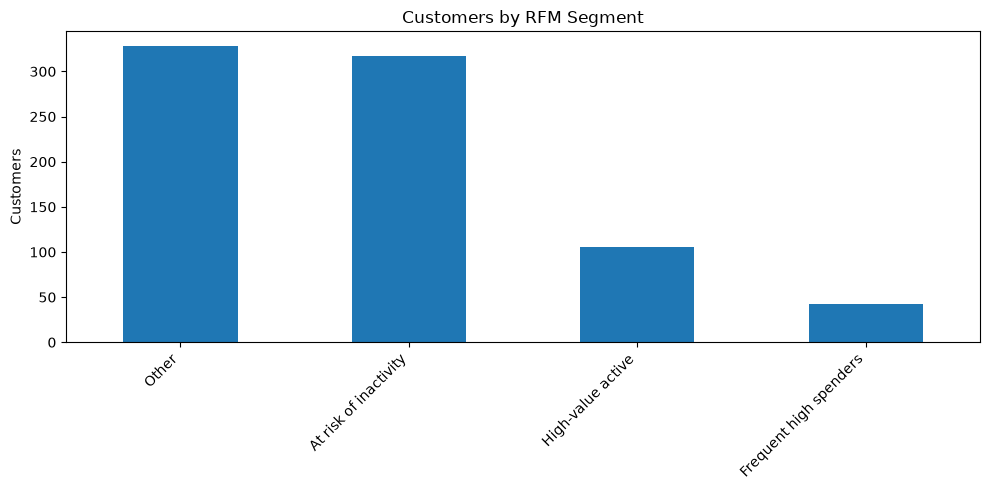

In [112]:
snapshot_date = data["Order Date"].max() + pd.Timedelta(days=1)
rfm = data.groupby("Customer ID").agg(
    Last_Order=("Order Date", "max"),
    Frequency=("Order ID", "nunique"),
    Monetary=("Sales", "sum")
)
rfm["Recency"] = (snapshot_date - rfm["Last_Order"]).dt.days

# Rank-based qcut helps handle repeated values in frequency/monetary measures.
rfm["R_Score"] = pd.qcut(rfm["Recency"].rank(method="first"), 5,
                         labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F_Score"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5,
                         labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M_Score"] = pd.qcut(rfm["Monetary"].rank(method="first"), 5,
                         labels=[1, 2, 3, 4, 5]).astype(int)
rfm["RFM Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)
rfm["Segment"] = np.select(
    [
        (rfm["R_Score"] >= 4) & (rfm["F_Score"] >= 4) & (rfm["M_Score"] >= 4),
        (rfm["R_Score"] <= 2),
        (rfm["F_Score"] >= 4) & (rfm["M_Score"] >= 4)
    ],
    ["High-value active", "At risk of inactivity", "Frequent high spenders"],
    default="Other"
)
display(rfm.sort_values("Monetary", ascending=False).head(20))
display(rfm.groupby("Segment").agg(
    Customers=("Monetary", "size"),
    Sales=("Monetary", "sum"),
    Average_Recency=("Recency", "mean")
))
bar_chart(rfm["Segment"].value_counts(), "Customers by RFM Segment",
          ylabel="Customers")


question 17 : best numeric variables with correlations 

,Sales,Quantity,Discount,Profit,Shipping Days
Sales,1.000000,0.200795,-0.028190,0.479064,-0.007354
Quantity,0.200795,1.000000,0.008623,0.066253,0.018298
Discount,-0.028190,0.008623,1.000000,-0.219487,0.000408
Profit,0.479064,0.066253,-0.219487,1.000000,-0.004649
Shipping Days,-0.007354,0.018298,0.000408,-0.004649,1.000000


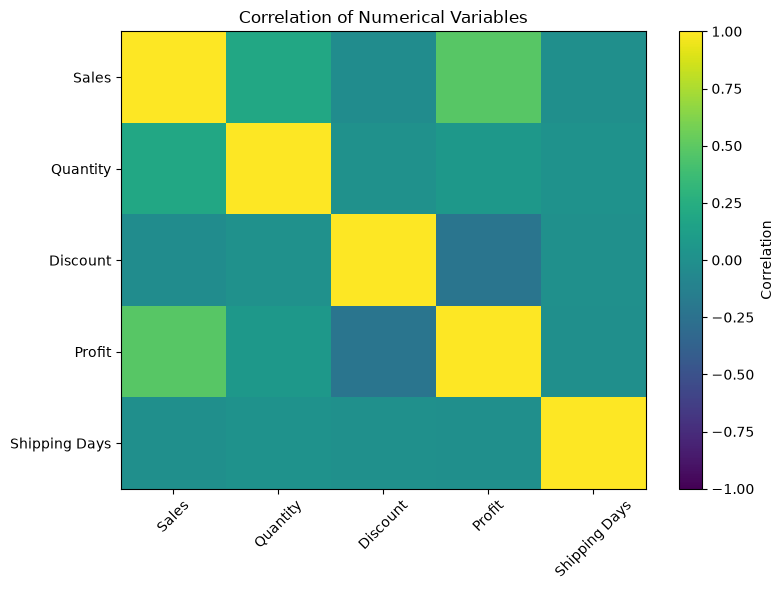

In [111]:
numeric_columns = ["Sales", "Quantity", "Discount", "Profit", "Shipping Days"]
correlations = data[numeric_columns].corr()
display(correlations)

plt.figure(figsize=(8, 6))
plt.imshow(correlations, aspect="auto", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(numeric_columns)), numeric_columns, rotation=45)
plt.yticks(range(len(numeric_columns)), numeric_columns)
plt.title("Correlation of Numerical Variables")
plt.tight_layout()
plt.show()


question 18 : best month and region duo with the best margin

Region,Central,East,South,West
Category,,,,
Furniture,-1.752808,1.462455,5.772619,4.554382
Office Supplies,5.316512,19.956873,15.906235,23.821180
Technology,19.773595,17.911961,13.437908,17.581383


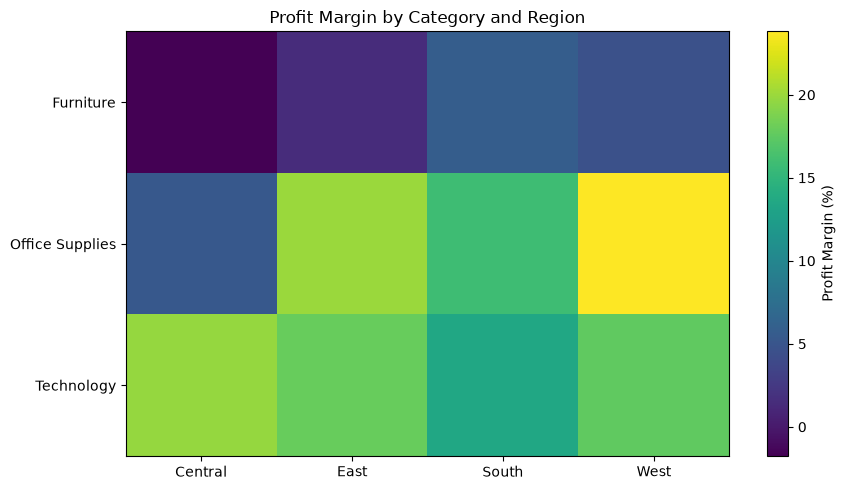

In [110]:
sales_grid = data.pivot_table(
    index="Category", columns="Region", values="Sales", aggfunc="sum"
)
profit_grid = data.pivot_table(
    index="Category", columns="Region", values="Profit", aggfunc="sum"
)
margin_grid = profit_grid / sales_grid * 100
display(margin_grid)

plt.figure(figsize=(9, 5))
plt.imshow(margin_grid, aspect="auto")
plt.colorbar(label="Profit Margin (%)")
plt.xticks(range(len(margin_grid.columns)), margin_grid.columns)
plt.yticks(range(len(margin_grid.index)), margin_grid.index)
plt.title("Profit Margin by Category and Region")
plt.tight_layout()
plt.show()


question 19 : which products with highest / least profit

,Sales,Profit,Quantity
Product Name,,,
Canon imageCLASS 2200 Advanced Copier,61599.824,25199.9280,20
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.384,7753.0390,31
Hewlett Packard LaserJet 3310 Copier,18839.686,6983.8836,38
Canon PC1060 Personal Laser Copier,11619.834,4570.9347,19
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.895,4094.9766,12
Ativa V4110MDD Micro-Cut Shredder,7699.890,3772.9461,11
"3D Systems Cube Printer, 2nd Generation, Magenta",14299.890,3717.9714,11
Plantronics Savi W720 Multi-Device Wireless Headset System,9367.290,3696.2820,24
Ibico EPK-21 Electric Binding System,15875.916,3345.2823,13


,Sales,Profit,Quantity
Product Name,,,
Cubify CubeX 3D Printer Double Head Print,11099.963,-8879.9704,9
Lexmark MX611dhe Monochrome Laser Printer,16829.901,-4589.9730,18
Cubify CubeX 3D Printer Triple Head Print,7999.980,-3839.9904,4
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,9917.640,-2876.1156,27
Bush Advantage Collection Racetrack Conference Table,9544.725,-1934.3976,33
GBC DocuBind P400 Electric Binding System,17965.068,-1878.1662,27
Cisco TelePresence System EX90 Videoconferencing Unit,22638.480,-1811.0784,6
Martin Yale Chadless Opener Electric Letter Opener,16656.200,-1299.1836,22
Balt Solid Wood Round Tables,6518.754,-1201.0581,19


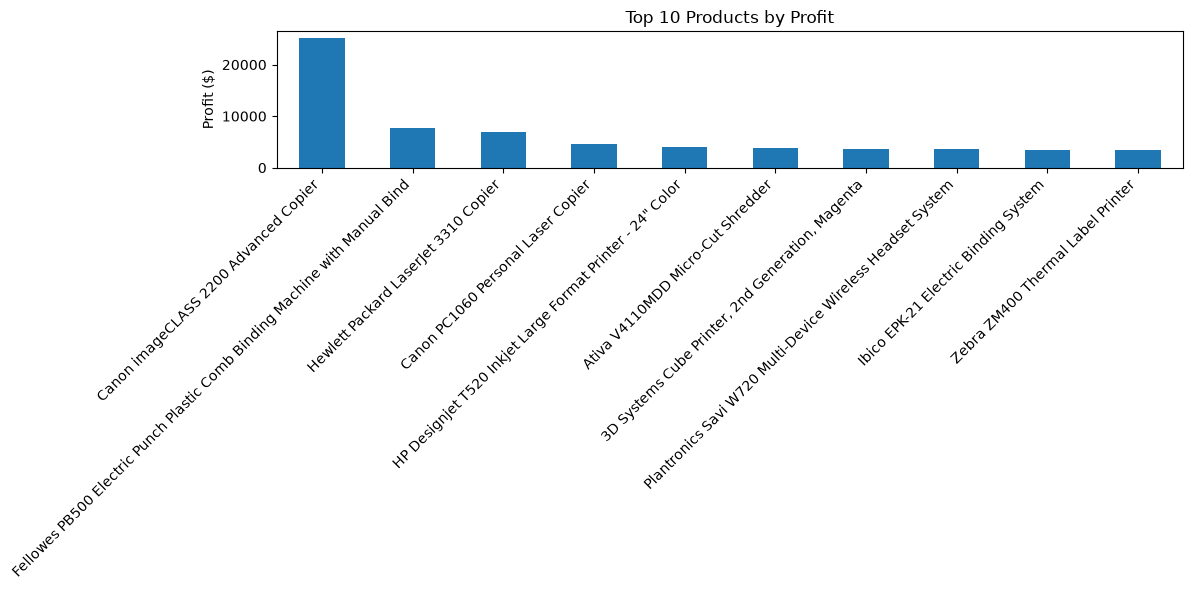

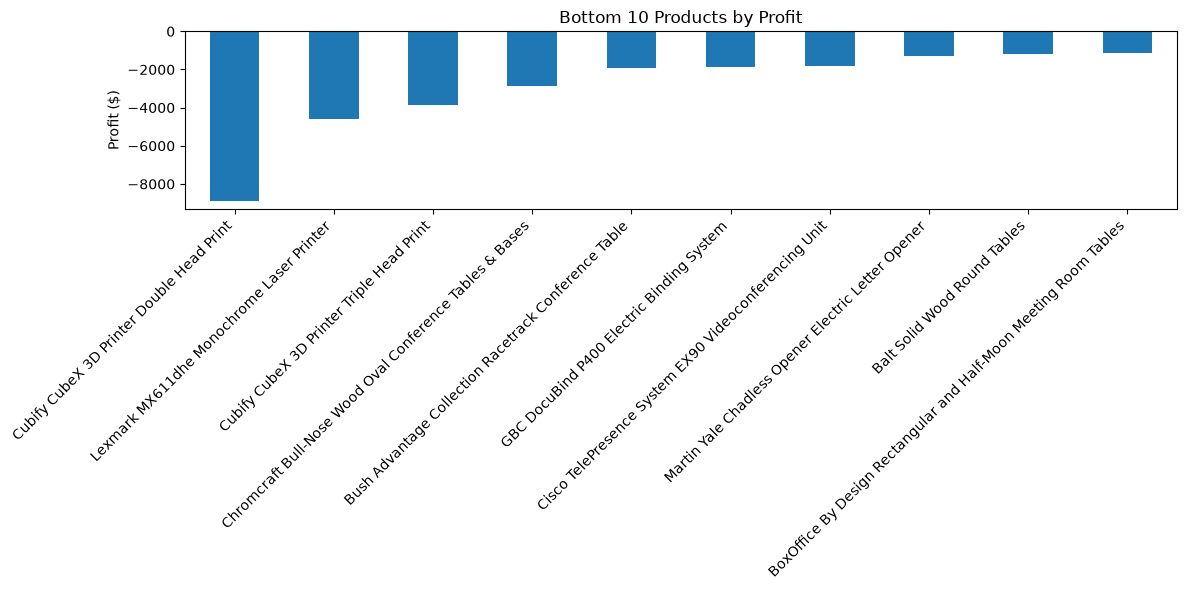

In [109]:
products = data.groupby("Product Name").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Quantity=("Quantity", "sum")
)
display(products.nlargest(10, "Profit"))
display(products.nsmallest(10, "Profit"))
bar_chart(products.nlargest(10, "Profit")["Profit"], "Top 10 Products by Profit",ylabel="Profit ($)", figsize=(12, 6))
bar_chart(products.nsmallest(10, "Profit")["Profit"], "Bottom 10 Products by Profit",ylabel="Profit ($)", figsize=(12, 6))


question 20 : does larger basket equales high orders values

,Order_Value,Order_Profit,Basket_Lines,Total_Units,Unique_Products
count,5009.000000,5009.000000,5009.000000,5009.000000,5009.000000
mean,458.614666,57.176487,1.995209,7.560990,1.993611
std,954.730953,344.937752,1.410671,6.220034,1.408823
min,0.556000,-6892.374800,1.000000,1.000000,1.000000
25%,37.630000,2.052500,1.000000,3.000000,1.000000
50%,151.960000,16.275800,1.000000,6.000000,1.000000
75%,512.064000,68.686800,2.000000,10.000000,2.000000
max,23661.228000,8762.389100,14.000000,52.000000,14.000000


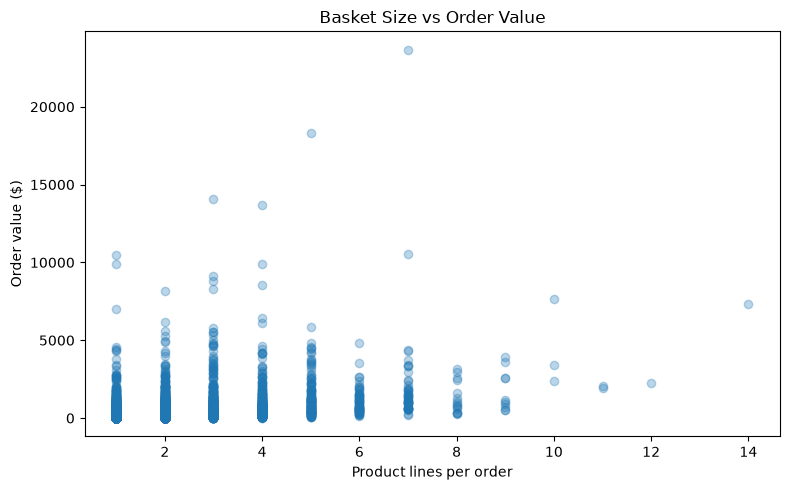

Correlation between basket lines and order value: 0.37520430168761265


In [105]:
orders = data.groupby("Order ID").agg(
    Order_Value=("Sales", "sum"),
    Order_Profit=("Profit", "sum"),
    Basket_Lines=("Product ID", "size"),
    Total_Units=("Quantity", "sum"),
    Unique_Products=("Product ID", "nunique")
)
display(orders.describe())

plt.figure(figsize=(8, 5))
plt.scatter(orders["Basket_Lines"], orders["Order_Value"], alpha=0.3)
plt.title("Basket Size vs Order Value")
plt.xlabel("Product lines per order")
plt.ylabel("Order value ($)")
plt.tight_layout()
plt.show()

print("Correlation between basket lines and order value:",
      orders["Basket_Lines"].corr(orders["Order_Value"]))


question 21 : how big of an affect does loss do

Loss-making lines          1871.000000
Loss-making lines (%)        18.721233
Total losses ($)         156131.285700
Profitable lines           8058.000000
Zero-profit lines            65.000000
Net profit ($)           286397.021700
dtype: float64

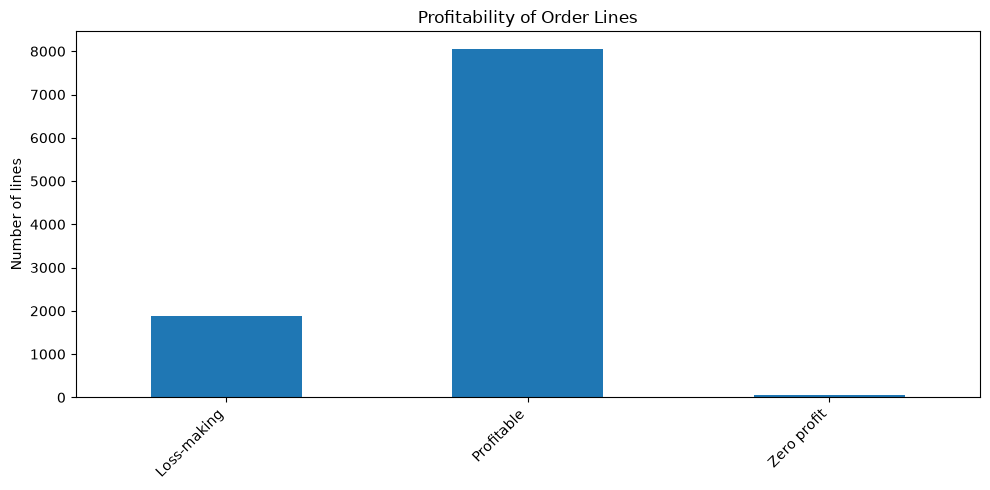

In [104]:
loss_lines = data[data["Profit"] < 0]
profitable_lines = data[data["Profit"] > 0]
zero_profit_lines = data[data["Profit"] == 0]

loss_summary = pd.Series({
    "Loss-making lines": len(loss_lines),
    "Loss-making lines (%)": len(loss_lines) / len(data) * 100,
    "Total losses ($)": -loss_lines["Profit"].sum(),
    "Profitable lines": len(profitable_lines),
    "Zero-profit lines": len(zero_profit_lines),
    "Net profit ($)": data["Profit"].sum()
})
display(loss_summary)

profitability_counts = pd.Series({
    "Loss-making": len(loss_lines),
    "Profitable": len(profitable_lines),
    "Zero profit": len(zero_profit_lines)
})
bar_chart(profitability_counts, "Profitability of Order Lines",
          ylabel="Number of lines")


question 22 : Are losses concentrated in certain subcategories or discount levels?

Sub-Category
Binders        38510.4964
Tables         32412.1483
Machines       30118.6682
Bookcases      12152.2060
Chairs          9880.8413
Appliances      8629.6412
Phones          7530.6235
Furnishings     6490.9134
Storage         6426.3038
Supplies        3015.6219
Accessories      930.6265
Fasteners         33.1952
Name: Profit, dtype: float64

Discount
0.70    40075.3569
0.80    30539.0392
0.40    25787.8268
0.50    20506.4281
0.20    17258.0654
0.30    10777.6879
0.60     5944.6552
0.45     2493.1111
0.32     2391.1377
0.15      328.7030
0.10       29.2744
Name: Profit, dtype: float64

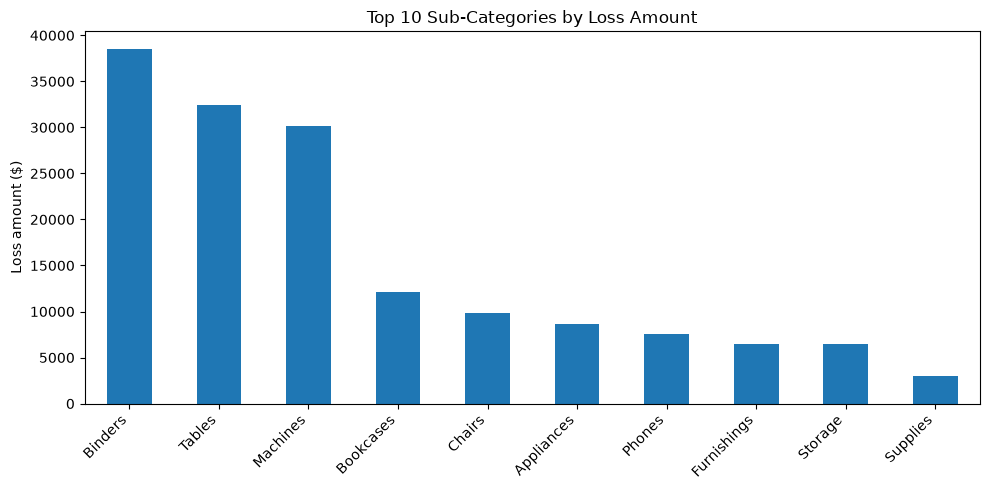

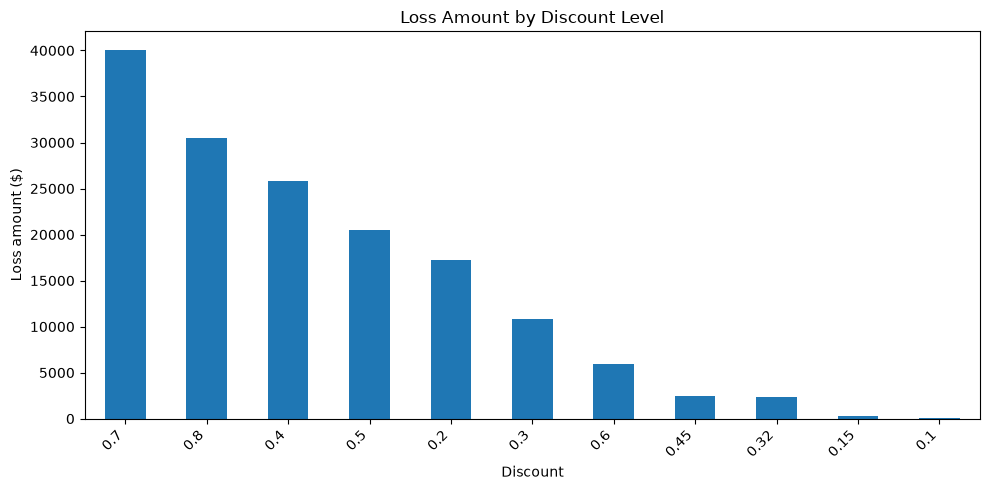

Discount,0.00,0.10,0.15,0.20,0.30,0.32,0.40,0.45,0.50,0.60,0.70,0.80
Sub-Category,,,,,,,,,,,,
Accessories,35289.2539,0.0000,0.0000,6647.3818,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
Appliances,23183.7361,1086.0808,0.0000,2497.8297,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,-8629.6412
Art,5380.6006,0.0000,0.0000,1147.1864,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
Binders,39314.4507,0.0000,0.0000,29417.8090,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,-16601.0984,-21909.3980
Bookcases,6075.7117,0.0000,1418.9915,130.5022,-555.8726,-2391.1377,0.0000,0.0000,-4255.8117,0.0000,-3894.9394,0.0000
Chairs,21933.0961,7111.0119,0.0000,4283.1750,-6737.1167,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
Copiers,35556.1349,0.0000,0.0000,17878.7148,0.0000,0.0000,2182.9752,0.0000,0.0000,0.0000,0.0000,0.0000
Envelopes,4976.9844,0.0000,0.0000,1987.1923,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
Fasteners,652.2052,0.0000,0.0000,297.3130,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


In [103]:
loss_lines = data.loc[data["Profit"] < 0]

loss_by_subcategory = (
    loss_lines.groupby("Sub-Category")["Profit"]
    .sum()
    .abs()
    .sort_values(ascending=False)
)
loss_by_discount = (
    loss_lines.groupby("Discount")["Profit"].sum().abs().sort_values(ascending=False)
)
display(loss_by_subcategory)
display(loss_by_discount)
bar_chart(loss_by_subcategory.head(10), "Top 10 Sub-Categories by Loss Amount",
          ylabel="Loss amount ($)")
bar_chart(loss_by_discount, "Loss Amount by Discount Level",xlabel="Discount", ylabel="Loss amount ($)")

subcategory_discount = data.pivot_table(
index="Sub-Category", columns="Discount", values="Profit",aggfunc="sum", fill_value=0)
display(subcategory_discount)


question 23 : How does year-on-year sales growth vary by region?

Region,Central,East,South,West
year-trends,,,,
2014,103838.1646,128680.457,103845.8435,147883.0330
2015,102874.2220,156332.057,71359.9805,139966.2495
2016,147429.3760,180685.822,93610.2235,187480.1765
2017,147098.1282,213082.904,122905.8575,250128.3655


Region,Central,East,South,West
year-trends,,,,
2014,NaN,NaN,NaN,NaN
2015,-0.928312,21.488578,-31.282776,-5.353409
2016,43.310319,15.578228,31.180282,33.946703
2017,-0.224682,17.930063,31.295336,33.415900


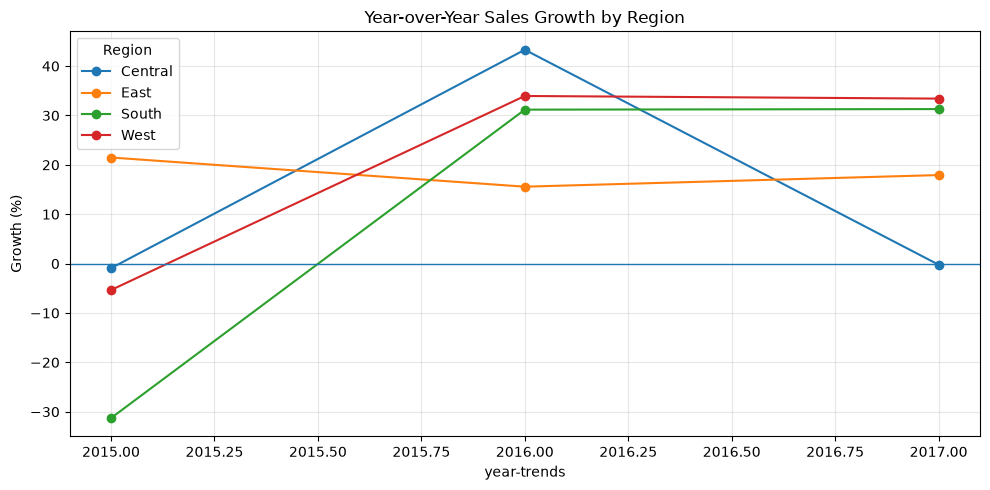

In [100]:
regional_yearly = data.pivot_table(
    index="year-trends", columns="Region", values="Sales", aggfunc="sum"
)
regional_growth_pct = regional_yearly.pct_change() * 100
display(regional_yearly)
display(regional_growth_pct)

regional_growth_pct.plot(marker="o", figsize=(10, 5),
                         title="Year-over-Year Sales Growth by Region")
plt.ylabel("Growth (%)")
plt.axhline(0, linewidth=1)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


question 24 : How do sales, profit, and margin change every 1/4 year 

,Sales,Profit,Profit Margin (%)
Quarter,,,
2014Q1,74447.7960,3811.2290,5.119331
2014Q2,86538.7596,11204.0692,12.946880
2014Q3,143633.2123,12804.7218,8.914875
2014Q4,179627.7302,21723.9541,12.093876
2015Q1,68851.7386,9264.9416,13.456366
2015Q2,89124.1870,12190.9224,13.678579
2015Q3,130259.5752,16853.6194,12.938488
2015Q4,182297.0082,23309.1203,12.786343
2016Q1,93237.1810,11441.3708,12.271253


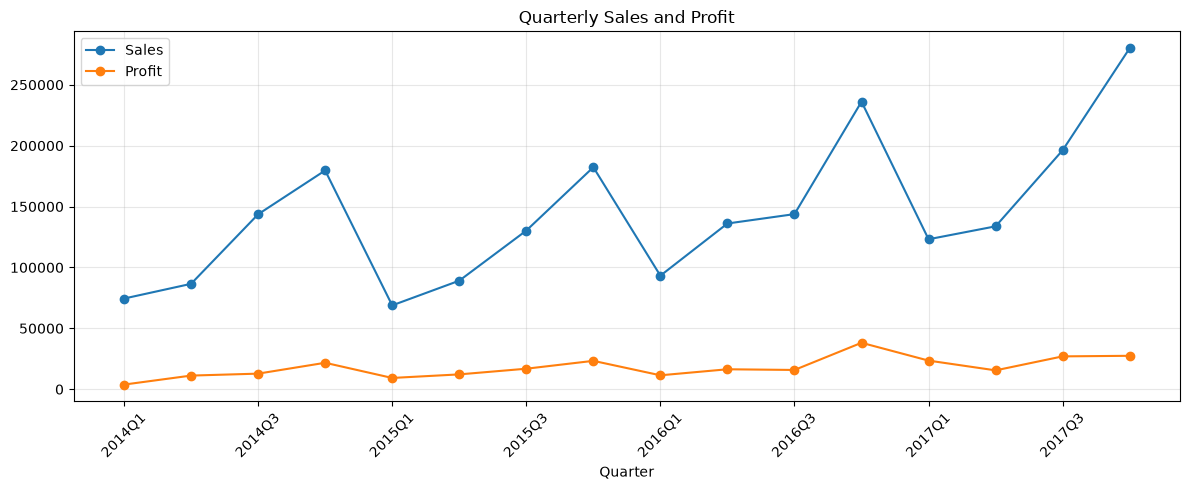

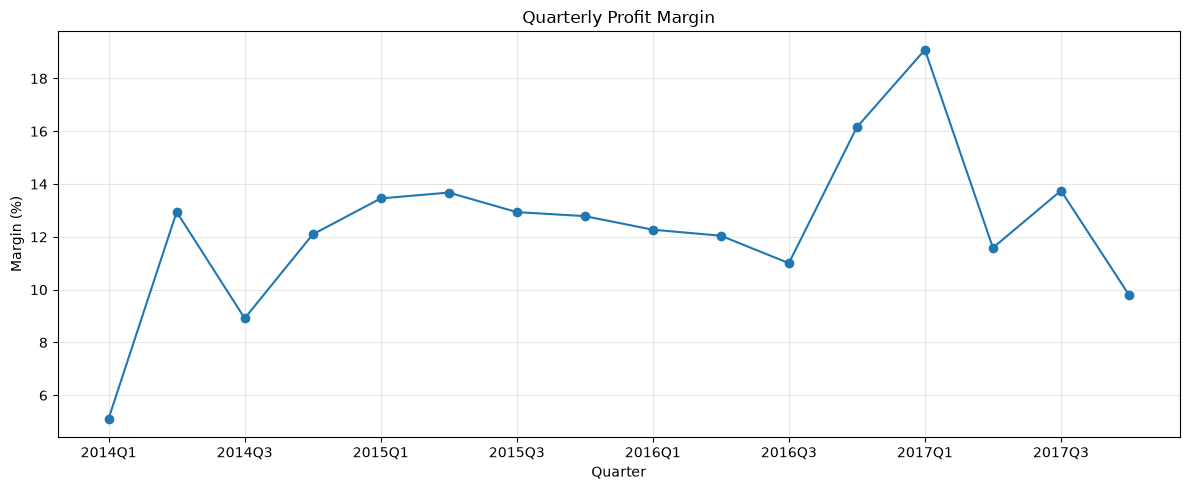

In [98]:
quarterly = data.groupby("Quarter").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
quarterly["Profit Margin (%)"] = profit_margin(quarterly)
display(quarterly)

quarterly[["Sales", "Profit"]].plot(
    marker="o", figsize=(12, 5), title="Quarterly Sales and Profit"
)
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

line_chart(quarterly["Profit Margin (%)"], "Quarterly Profit Margin",
           "Quarter", "Margin (%)", figsize=(12, 5))


question 25 : which week with the most unique orders

Weekday
Monday       920
Tuesday      558
Wednesday    182
Thursday     746
Friday       916
Saturday     837
Sunday       850
Name: Order ID, dtype: int64

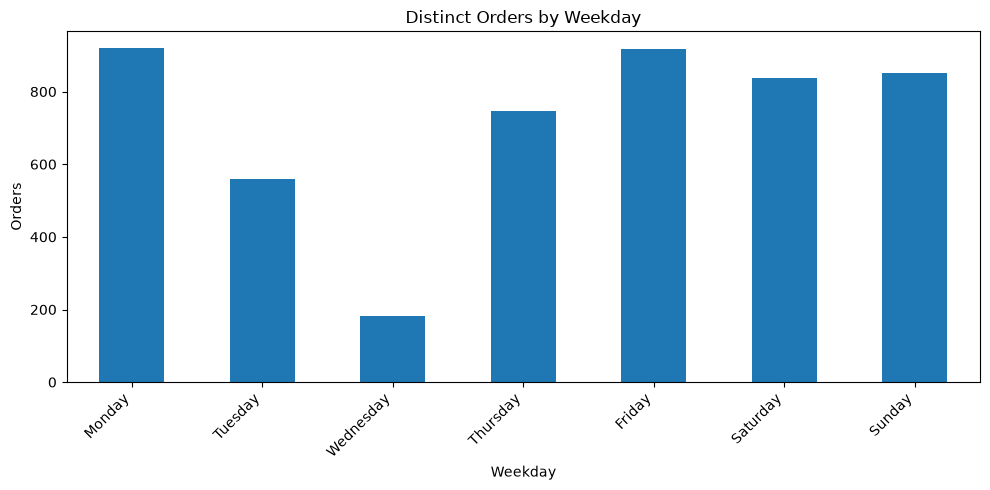

In [97]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday",
                 "Friday", "Saturday", "Sunday"]
data["Weekday"] = data["Order Date"].dt.day_name()
weekday_orders = ( data.groupby("Weekday")["Order ID"].nunique().reindex(weekday_order, fill_value=0))
display(weekday_orders)
bar_chart(weekday_orders, "Distinct Orders by Weekday",
          xlabel="Weekday", ylabel="Orders")
